# Laboratorium 3 - segmentacje

## Przygotowanie

 * pobierz zbiory danych do katalogu z notebookiem - ze źródeł albo z Teamsów:
   * BeerAdvocate: https://data.world/socialmediadata/beeradvocate
   * Steam: https://cseweb.ucsd.edu/~jmcauley/datasets.html#steam_data:
     * [australian_users_items.json.gz](https://mcauleylab.ucsd.edu/public_datasets/data/steam/australian_users_items.json.gz)
     * [australian_user_reviews.json.gz](https://mcauleylab.ucsd.edu/public_datasets/data/steam/australian_user_reviews.json.gz)
     * [steam_games.json.gz](https://cseweb.ucsd.edu/~wckang/steam_games.json.gz)
 * [opcjonalnie] Utwórz wirtualne środowisko
 `python3 -m venv ./recsyslab3`
 * zainstaluj potrzebne biblioteki:
 `pip3 install gensim scikit-learn matplotlib wordcloud`

## Część 1. - przygotowanie danych

In [52]:
# importujemy potrzebne pakiety

import ast
import csv
import gzip
from collections import Counter, defaultdict
from dataclasses import dataclass, field
from typing import Callable, Dict, Iterator, List, Optional, Protocol, Set, Tuple

from gensim.models import Word2Vec
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import AgglomerativeClustering, KMeans, SpectralClustering  # w sklearn.cluster znajdziesz tez inne algorytmy
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_samples
from sklearn.mixture import GaussianMixture
# GaussianMixture - jak chcemy zobaczyć słaby algorytm
from wordcloud import WordCloud

In [4]:
@dataclass(frozen=True)
class Params:
    min_item_count: int = 5  # minimalna liczba pozytywnych ocen elementu, by trafil do modelu
    vector_size: int = 20  # dlugosc wektorow osadzen
    window: int = 10  # rozmiar okna Word2Vec
    segments_count: int = 10  # na ile segmentow dzielimy populacje uzytkownikow
    top_n: int = 50  # liczba kategorii w opisie segmentu
    sample_size: int = 5000  # sylwetke i rzutowanie 2D liczymy na probce uzytkownikow
    percentiles: Tuple[int, ...] = (25, 50, 75, 95)
    seed: int = 42


PARAMS = Params()

In [ ]:
# wspolna reprezentacja danych - dla kazdego uzytkownika zbieramy listy lubianych i nielubianych elementow

@dataclass
class UserProfile:
    liked: List[str] = field(default_factory=list)
    disliked: List[str] = field(default_factory=list)

    @property
    def activity(self) -> int:
        return len(self.liked) + len(self.disliked)


@dataclass
class Dataset:
    name: str
    profiles: Dict[str, UserProfile]  # user_id -> profil
    item_categories: Dict[str, List[str]]  # item_id -> kategorie (styl piwa / tagi gry)

    def summary(self) -> str:
        categories = {category for item_categories in self.item_categories.values() for category in item_categories}
        liked = sum(len(profile.liked) for profile in self.profiles.values())
        disliked = sum(len(profile.disliked) for profile in self.profiles.values())
        return (f'{self.name}: {len(self.profiles)} users, {len(self.item_categories)} items, '
                f'{len(categories)} categories, {liked} liked, {disliked} disliked')


class DatasetLoader(Protocol):
    min_activity: int  # minimalna liczba lubianych + nielubianych elementow uzytkownika

    def load(self) -> Dataset: ...


def filter_inactive_users(dataset: Dataset, min_activity: int) -> Dataset:
    # odsiewamy uzytkownikow, o ktorych wiemy zbyt malo
    profiles = {user_id: profile for user_id, profile in dataset.profiles.items() if profile.activity >= min_activity}
    return Dataset(dataset.name, profiles, dataset.item_categories)

### BeerAdvocate

Recenzje piw - elementami są piwa, kategorią jest styl piwa. Ocena (`review_overall`) w skali 1-5.

In [6]:
@dataclass(frozen=True)
class BeerAdvocateLoader:
    path: str = 'socialmediadata-beeradvocate/data/beer_reviews.csv'
    positive_threshold: float = 4  # oceny >= progu traktujemy jako pozytywne
    negative_threshold: float = 2  # oceny <= progu traktujemy jako negatywne
    min_activity: int = 10

    def load(self) -> Dataset:
        profiles: Dict[str, UserProfile] = defaultdict(UserProfile)
        item_categories: Dict[str, List[str]] = {}
        with open(self.path, encoding='utf-8', newline='') as datafile:
            for row in csv.DictReader(datafile):
                user_id, item_id = row['review_profilename'], row['beer_beerid']
                if not user_id:
                    continue
                item_categories[item_id] = [row['beer_style']]
                rating = float(row['review_overall'])
                if rating >= self.positive_threshold:
                    profiles[user_id].liked.append(item_id)
                elif rating <= self.negative_threshold:
                    profiles[user_id].disliked.append(item_id)
        return Dataset('beeradvocate', dict(profiles), item_categories)

### Steam

Gry posiadane przez użytkowników platformy Steam - elementami są gry, kategoriami tagi gier. Nie mamy ocen, więc:
 * grę **lubianą** wyznaczamy na podstawie czasu gry (`playtime_forever`, w minutach),
 * grę **nielubianą** - na podstawie recenzji z `recommend == False`; opcjonalnie także gry posiadane, ale prawie nieuruchamiane.

Pliki zawierają słowniki Pythona (nie JSON), dlatego czytamy je przez `ast.literal_eval`. Wczytywanie trwa kilka minut.

In [7]:
def read_python_literals(path: str) -> Iterator[dict]:
    with gzip.open(path, 'rt', encoding='utf-8') as datafile:
        for line in datafile:
            yield ast.literal_eval(line)


@dataclass(frozen=True)
class SteamLoader:
    users_items_path: str = 'steam/australian_users_items.json.gz'
    reviews_path: str = 'steam/australian_user_reviews.json.gz'
    games_path: str = 'steam/steam_games.json.gz'
    liked_playtime: int = 120  # gry grane co najmniej tyle minut traktujemy jako lubiane
    disliked_playtime: Optional[int] = None  # jesli ustawione, gry grane krocej niz tyle minut traktujemy jako nielubiane
    min_activity: int = 50

    def load(self) -> Dataset:
        item_categories = self._load_item_categories()
        not_recommended = self._load_not_recommended(item_categories)
        profiles: Dict[str, UserProfile] = {}
        for user in read_python_literals(self.users_items_path):
            user_id = user['user_id']
            if user_id in profiles:  # w pliku zdarzaja sie zduplikowani uzytkownicy
                continue
            disliked = not_recommended.get(user_id, set())
            profile = UserProfile(disliked=list(disliked))
            for item in user['items']:
                item_id, playtime = item['item_id'], item['playtime_forever']
                if item_id not in item_categories or item_id in disliked:
                    continue
                if playtime >= self.liked_playtime:
                    profile.liked.append(item_id)
                elif self.disliked_playtime is not None and playtime < self.disliked_playtime:
                    profile.disliked.append(item_id)
            profiles[user_id] = profile
        return Dataset('steam', profiles, item_categories)

    def _load_item_categories(self) -> Dict[str, List[str]]:
        # uzywamy tagow, a gdy ich brak - gatunkow; pomijamy gry bez zadnych kategorii
        item_categories = {}
        for game in read_python_literals(self.games_path):
            categories = game.get('tags') or game.get('genres')
            if 'id' in game and categories:
                item_categories[game['id']] = categories
        return item_categories

    def _load_not_recommended(self, item_categories: Dict[str, List[str]]) -> Dict[str, Set[str]]:
        not_recommended: Dict[str, Set[str]] = defaultdict(set)
        for user in read_python_literals(self.reviews_path):
            for review in user['reviews']:
                if not review['recommend'] and review['item_id'] in item_categories:
                    not_recommended[user['user_id']].add(review['item_id'])
        return not_recommended

### Wybór zbioru danych

Wybierz jeden zbiór danych - na nim wykonasz wszystkie kolejne części. Wczytywany jest tylko wybrany zbiór.

In [8]:
DATASET_NAME = 'beeradvocate'  # 'beeradvocate' lub 'steam'

LOADERS: Dict[str, DatasetLoader] = {
    'beeradvocate': BeerAdvocateLoader(),
    'steam': SteamLoader(),
}

loader = LOADERS[DATASET_NAME]
dataset = filter_inactive_users(loader.load(), loader.min_activity)
print(dataset.summary())

beeradvocate: 9169 users, 66051 items, 104 categories, 945996 liked, 57291 disliked


## Część 2. - osadzenia użytkowników

In [9]:
# trenujemy model Item2Vec - "zdaniami" sa listy elementow lubianych przez uzytkownikow

model = Word2Vec(
    sentences=[profile.liked for profile in dataset.profiles.values()],
    vector_size=PARAMS.vector_size,
    window=PARAMS.window,
    min_count=PARAMS.min_item_count,
    workers=4,
    seed=PARAMS.seed,
)

In [60]:
# na podstawie modelu obliczamy wektorowa reprezentacje uzytkownikow

UserVectors = Dict[str, np.ndarray]
UserVectorizer = Callable[[UserProfile, Word2Vec], Optional[np.ndarray]]

def mean_user_vector(profile: UserProfile, model: Word2Vec) -> Optional[np.ndarray]:
    # srednia z wektorow lubianych elementow; pomijamy elementy odrzucone przez min_count
    model_vectors = [model.wv[item_id] for item_id in profile.liked if item_id in model.wv]
    if not model_vectors:
        return None
    return np.mean(model_vectors, axis=0)


def compute_user_vectors(profiles: Dict[str, UserProfile], model: Word2Vec, vectorizer: UserVectorizer) -> UserVectors:
    # pomijamy uzytkownikow, dla ktorych nie da sie policzyc wektora
    user_vectors: UserVectors = {}
    for user_id, profile in profiles.items():
        vector = vectorizer(profile, model)
        if vector is not None:
            user_vectors[user_id] = vector
    return user_vectors


user_vectors = compute_user_vectors(dataset.profiles, model, mean_user_vector)
print(f'Users with vectors: {len(user_vectors)}')

Users with vectors: 9168


## Część 3. - klasteryzacja

In [61]:
# klastrujemy uzytkownikow - porownaj co najmniej 2 rozne algorytmy

from sklearn.cluster import MeanShift


Segmentation = Dict[str, int]  # user_id -> segment


def segment_users(user_vectors: UserVectors, segments_count: int, algorithm: str, seed: int = PARAMS.seed) -> Segmentation:
    X = list(user_vectors.values())
    if algorithm == 'kmeans':
        clustering = KMeans(n_clusters=segments_count, random_state=seed).fit(X)
        clusters = clustering.labels_
    elif algorithm == 'agglomerative':
        clustering = AgglomerativeClustering(n_clusters=segments_count).fit(X)
        clusters = clustering.labels_
    elif algorithm == 'gmm':
        clustering = GaussianMixture(n_components=segments_count, random_state=seed).fit(X)
        clusters = clustering.predict(list(user_vectors.values()))
    elif algorithm == 'spectral':
        clustering = SpectralClustering(n_clusters=segments_count, random_state=seed).fit(X)
        clusters = clustering.labels_
    segmentation = {user_id: cluster for user_id, cluster in zip(user_vectors.keys(), clusters)}
    return segmentation


def segment_sizes(segmentation: Segmentation) -> Counter:
    return Counter(segmentation.values())

In [62]:
algorithms = ['kmeans', 'gmm', 'agglomerative', 'spectral']
segmentations: Dict[str, Segmentation] = {
    algorithm: segment_users(user_vectors, PARAMS.segments_count, algorithm) for algorithm in algorithms
}

for algorithm, segmentation in segmentations.items():
    print(f'{algorithm:<15}{sorted(segment_sizes(segmentation).values(), reverse=True)}')

kmeans         [1956, 1379, 1349, 979, 776, 742, 538, 525, 521, 403]
gmm            [1635, 1541, 1033, 889, 885, 786, 725, 634, 547, 493]
agglomerative  [2228, 1853, 1348, 1323, 772, 529, 460, 289, 222, 144]
spectral       [9144, 4, 3, 3, 3, 3, 2, 2, 2, 2]


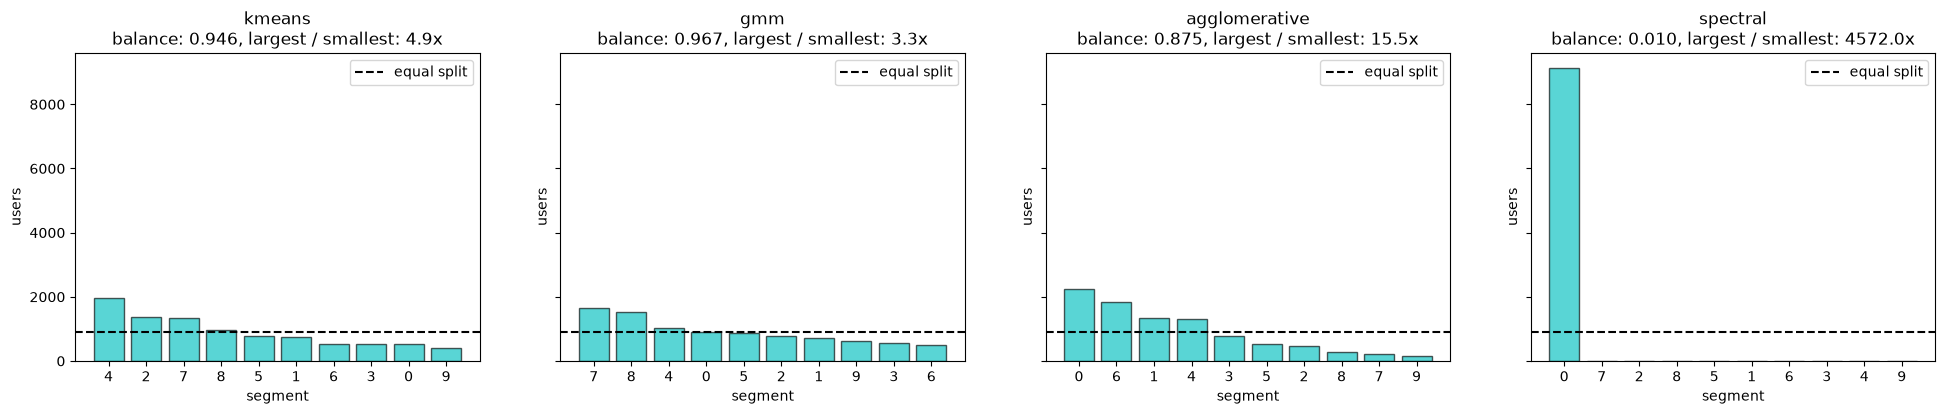

In [64]:
# czy podzial na segmenty jest rownomierny?

def segment_balance(segmentation: Segmentation, segments_count: int = PARAMS.segments_count) -> float:
    # znormalizowana entropia licznosci segmentow: 1 - rowny podzial, blisko 0 - jeden dominujacy segment
    sizes = np.array(list(segment_sizes(segmentation).values()))
    shares = sizes / sizes.sum()
    return float(-(shares * np.log(shares)).sum() / np.log(segments_count))


def plot_segment_sizes(segmentations: Dict[str, Segmentation]) -> None:
    _, axes = plt.subplots(1, len(segmentations), figsize=(6 * len(segmentations), 4), sharey=True, squeeze=False)
    for ax, (name, segmentation) in zip(axes[0], segmentations.items()):
        segments, sizes = zip(*segment_sizes(segmentation).most_common())
        ax.bar(range(len(sizes)), sizes, color='c', edgecolor='k', alpha=0.65)
        ax.axhline(len(segmentation) / PARAMS.segments_count, color='k', linestyle='dashed', linewidth=1.5, label='equal split')
        ax.set_xticks(range(len(sizes)), [str(segment) for segment in segments])
        title = f'{name}\nbalance: {segment_balance(segmentation):.3f}, largest / smallest: {sizes[0] / sizes[-1]:.1f}x'
        ax.set(title=title, xlabel='segment', ylabel='users')
        ax.legend()
    plt.show()


plot_segment_sizes(segmentations)

In [65]:
# metryka jakosci segmentacji - sylwetka przyjmuje wartosci z przedzialu [-1, 1], im wiecej, tym lepiej

@dataclass
class SilhouetteResult:
    per_sample: np.ndarray

    @property
    def mean(self) -> float:
        return float(self.per_sample.mean())

    def percentile(self, q: float) -> float:
        return float(np.percentile(self.per_sample, q))


def sample_users(users: List[str], sample_size: int = PARAMS.sample_size, seed: int = PARAMS.seed) -> List[str]:
    if len(users) <= sample_size:
        return users
    return list(np.random.default_rng(seed).choice(users, size=sample_size, replace=False))


def evaluate_segmentation(user_vectors: UserVectors, segmentation: Segmentation) -> SilhouetteResult:
    users = sample_users(list(segmentation))
    vectors = np.stack([user_vectors[user_id] for user_id in users])
    labels = np.array([segmentation[user_id] for user_id in users])
    return SilhouetteResult(silhouette_samples(vectors, labels))


def plot_silhouette(result: SilhouetteResult, title: str, percentiles: Tuple[int, ...] = PARAMS.percentiles) -> None:
    _, ax = plt.subplots(figsize=(10, 4))
    ax.hist(result.per_sample, bins=50, color='c', edgecolor='k', alpha=0.65)
    ax.axvline(result.mean, color='k', linestyle='dashed', linewidth=1.5, label=f'mean: {result.mean:.3f}')
    for q, color in zip(percentiles, plt.cm.Dark2.colors):
        value = result.percentile(q)
        ax.axvline(value, color=color, linestyle='dotted', linewidth=1.5, label=f'p{q}: {value:.3f}')
    ax.set(title=title, xlabel='silhouette', ylabel='users')
    ax.legend()
    plt.show()

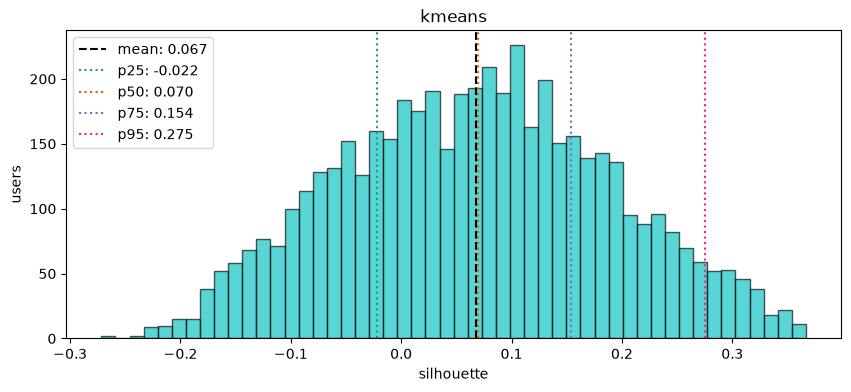

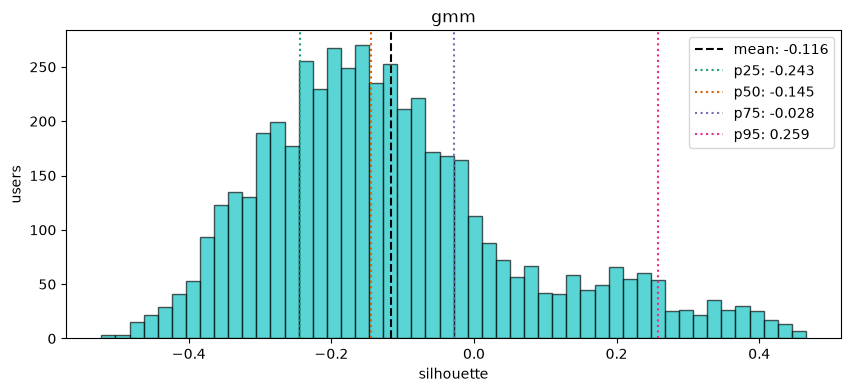

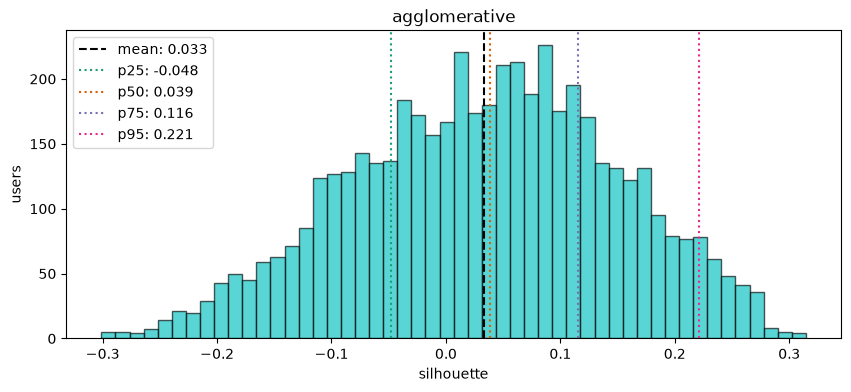

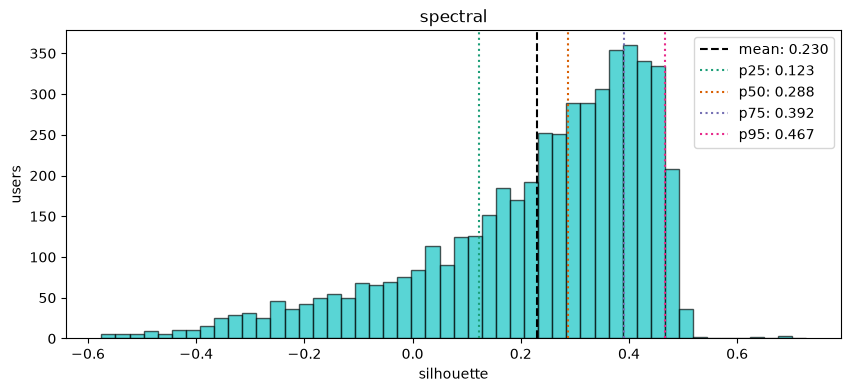

In [66]:
for algorithm, segmentation in segmentations.items():
    plot_silhouette(evaluate_segmentation(user_vectors, segmentation), algorithm)

### Wizualizacja 2D

Wektory użytkowników rzutujemy na płaszczyznę i kolorujemy według segmentu. Rzut zawsze gubi część informacji:
 * **PCA** - rzut liniowy, zachowuje globalny układ punktów, ale segmenty często na siebie nachodzą,
 * **t-SNE** - rzut nieliniowy, dobrze rozdziela lokalne skupiska, ale odległości między nimi i ich rozmiary są silniej zaburzone.

In [67]:
@dataclass
class Projection:
    method: str
    users: List[str]
    points: np.ndarray  # macierz (len(users), 2)


def project_users(user_vectors: UserVectors, method: str, seed: int = PARAMS.seed) -> Projection:
    users = sample_users(list(user_vectors))
    vectors = np.stack([user_vectors[user_id] for user_id in users])
    if method == 'pca':
        points = PCA(n_components=2, random_state=seed).fit_transform(vectors)
    elif method == 'tsne':
        points = TSNE(n_components=2, init='pca', random_state=seed).fit_transform(vectors)
    else:
        raise ValueError(f'Unknown projection method: {method}')
    return Projection(method, users, points)


def plot_projections(projections: List[Projection], segmentations: Dict[str, Segmentation]) -> None:
    # wiersze - metody rzutowania, kolumny - segmentacje; w kazdym wierszu te same punkty, rozne kolory
    rows, cols = len(projections), len(segmentations)
    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 6 * rows), squeeze=False, layout='constrained')
    colors = plt.get_cmap('tab10' if PARAMS.segments_count <= 10 else 'tab20').colors
    for row, projection in zip(axes, projections):
        for ax, (name, segmentation) in zip(row, segmentations.items()):
            point_colors = [colors[segmentation[user_id] % len(colors)] for user_id in projection.users]
            ax.scatter(*projection.points.T, c=point_colors, s=4, alpha=0.6)
            ax.set(title=f'{name} - {projection.method}', xticks=[], yticks=[])
    handles = [plt.Line2D([], [], marker='o', linestyle='', color=colors[segment % len(colors)], label=str(segment))
               for segment in range(PARAMS.segments_count)]
    fig.legend(handles=handles, title='segment', loc='outside right center')
    plt.show()

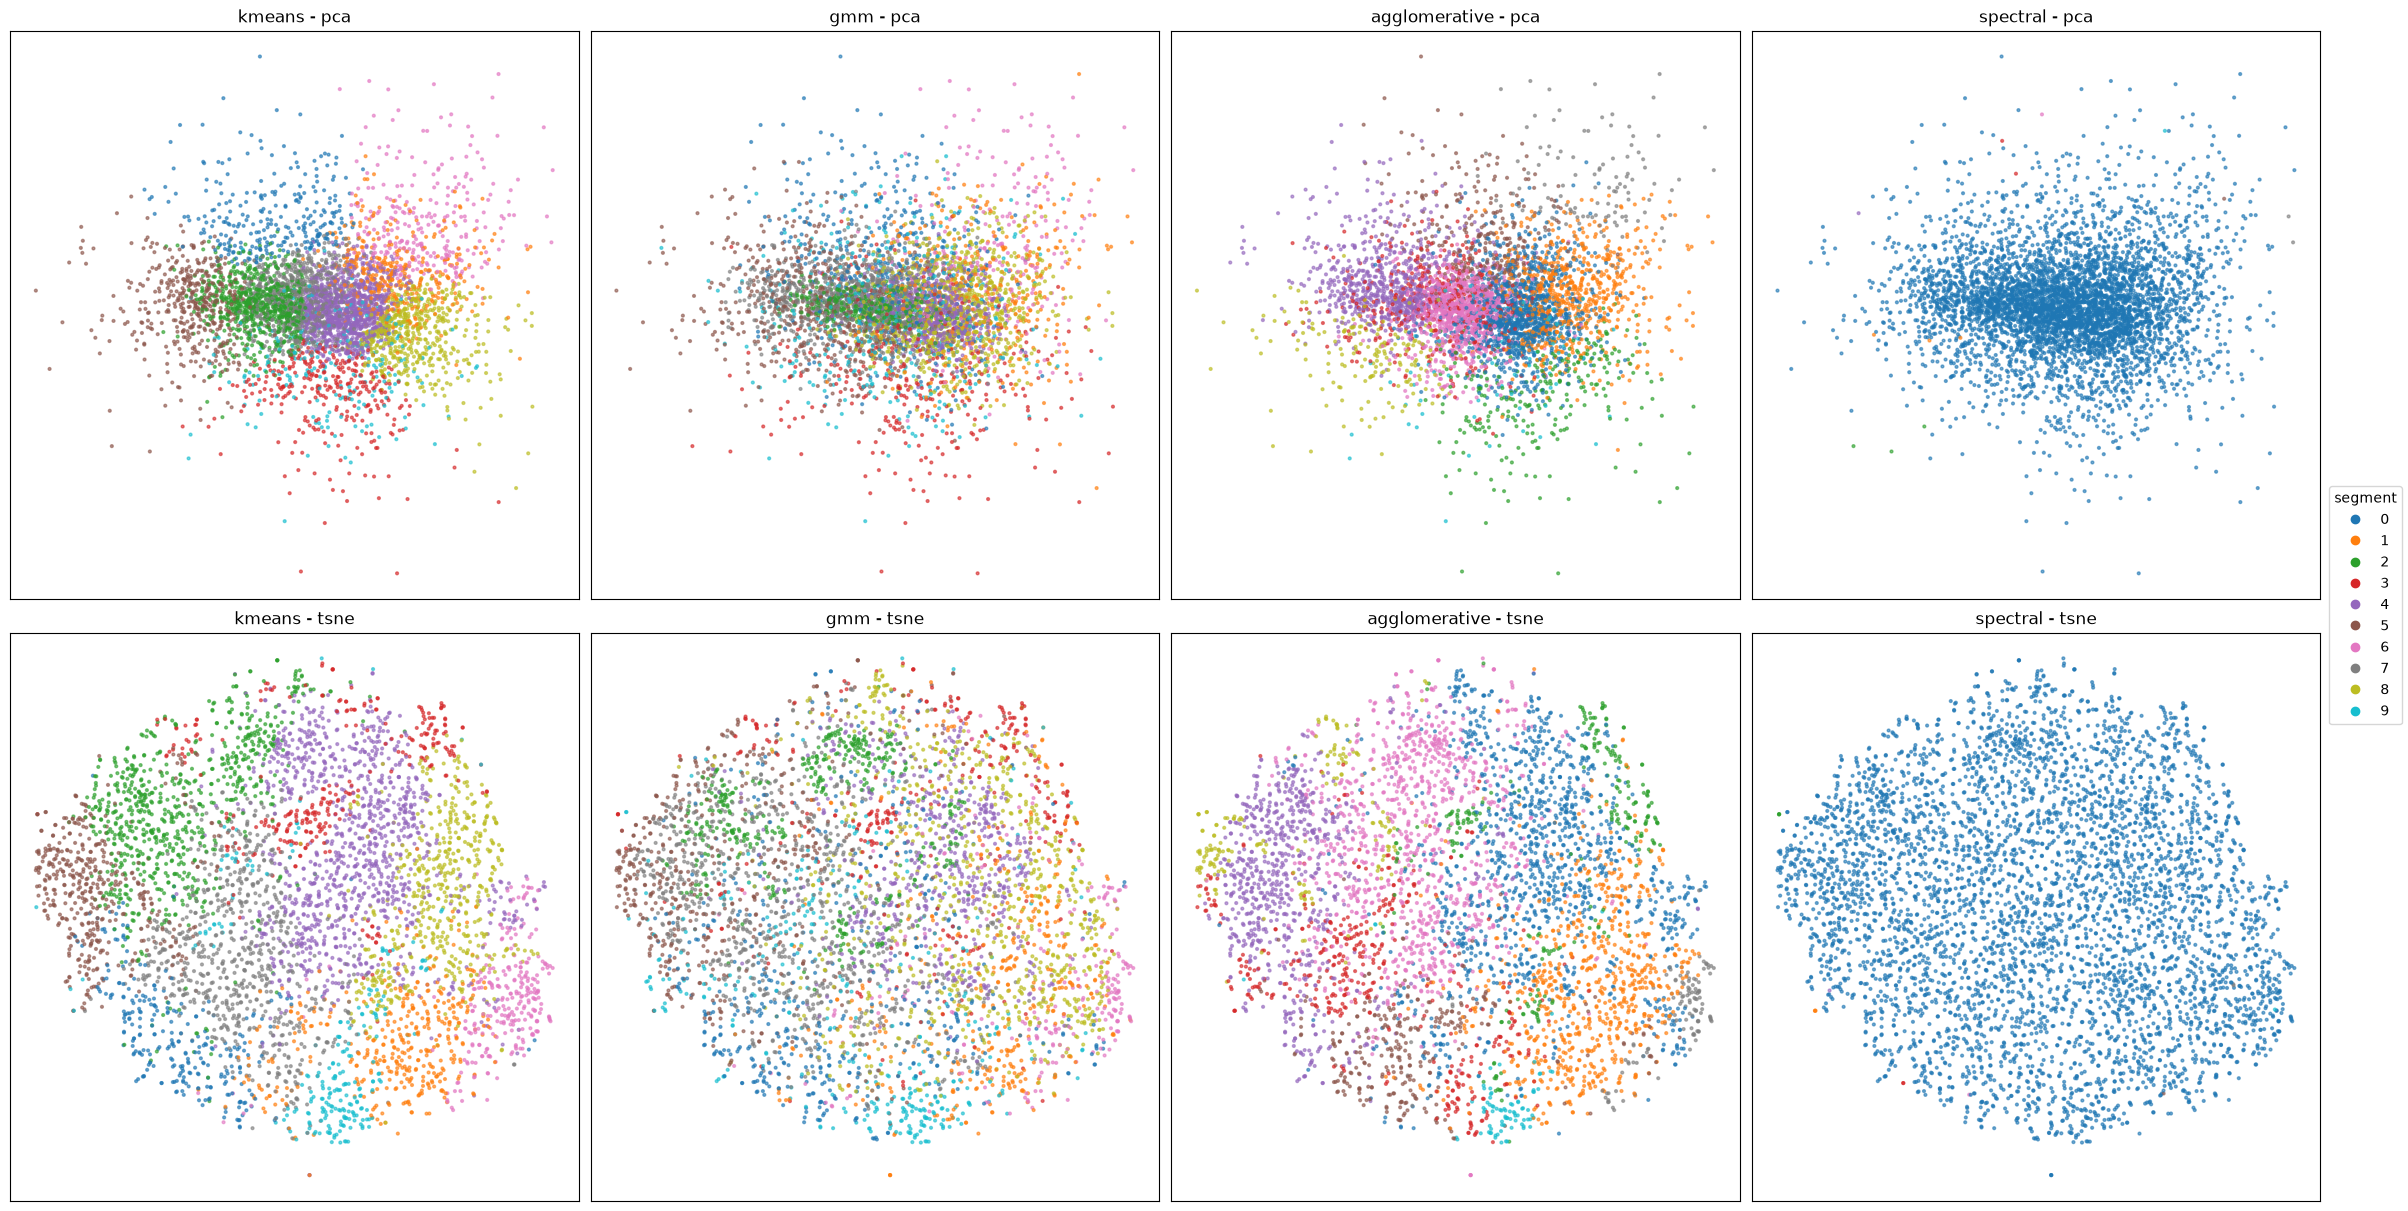

In [69]:
projections = [project_users(user_vectors, method) for method in ['pca', 'tsne']]
plot_projections(projections, segmentations)

## Część 3.5. - negative sampling

Wykonaj kroki obliczania embeddingów użytkowników, klasteryzacji z użyciem najlepszego według Ciebie algorytmu i obliczania sylwetki - ale tym razem embeddingi to średnia ważona, gdzie elementy `profile.liked` mają wagę `1`, a elementy `profile.disliked` mają wagę `-1`.

Pamiętaj, by wykorzystać ten sam wytrenowany już wcześniej model Item2Vec, który oblicza embeddingi poszczególnych elementów.

In [70]:
def weighted_user_vector(user_profile: UserProfile, model: Word2Vec) -> Optional[np.ndarray]:
    word_vect_liked = [model.wv[item_id] for item_id in user_profile.liked if item_id in model.wv]
    word_vect_disliked = [- model.wv[item_id] for item_id in user_profile.disliked if item_id in model.wv]
    if not word_vect_liked and not word_vect_disliked:
        return None
    return np.mean(word_vect_liked + word_vect_disliked, axis=0)


user_vectors_w: UserVectors = compute_user_vectors(dataset.profiles, model, weighted_user_vector)
print(f'Users with vectors: {len(user_vectors_w)}')

Users with vectors: 9169


In [71]:
seg = {'kmeans': segment_users(user_vectors_w, PARAMS.segments_count, 'kmeans', PARAMS.seed)}

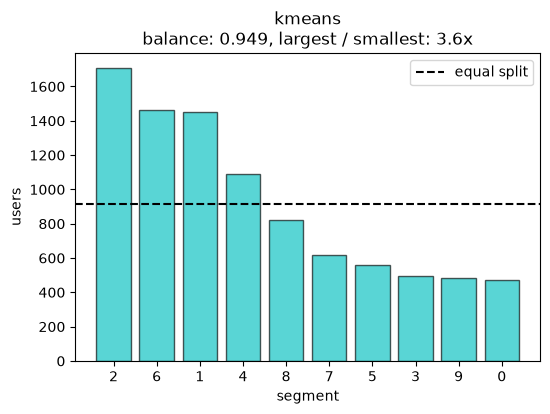

In [72]:
plot_segment_sizes(seg)

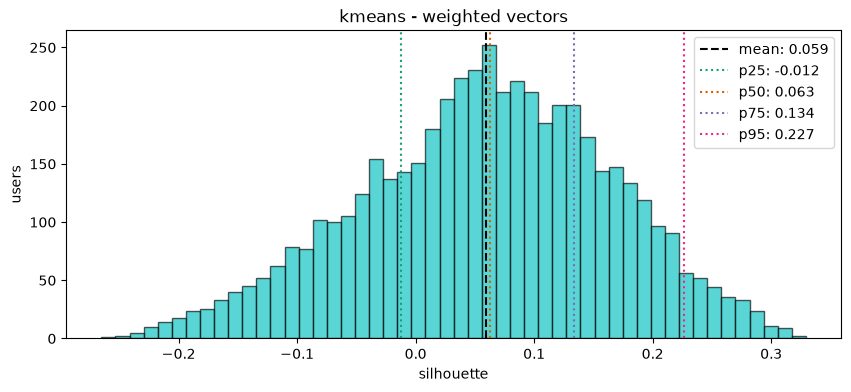

In [73]:
plot_silhouette(evaluate_segmentation(user_vectors_w, seg['kmeans']), 'kmeans - weighted vectors')

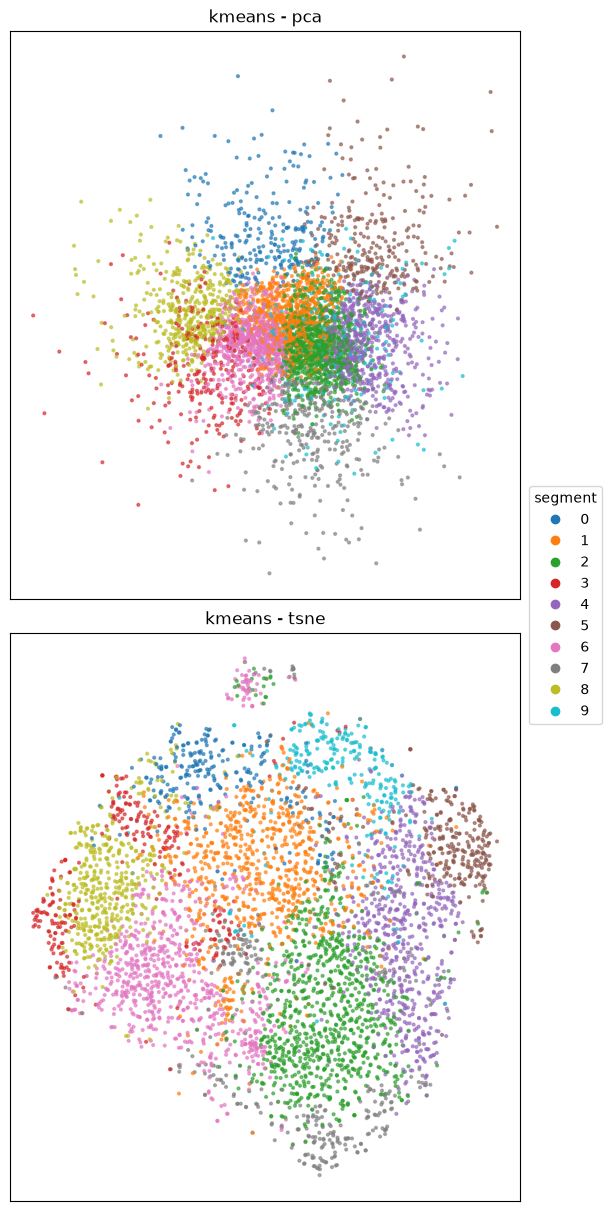

In [74]:
plot_projections([project_users(user_vectors_w, method) for method in ['pca', 'tsne']], seg)

## Część 4. - opisy segmentów

Część 4. i 5. wykonaj dla jednego wybranego algorytmu liczenia embeddingów i jednego algorytmu klasteryzacji.

In [75]:
chosen_segmentation = segmentations['kmeans']

In [81]:
# obliczamy popularnosc kategorii w segmentach oraz w calej populacji

CategoryCounts = Dict[int, Counter]  # segment -> {kategoria -> liczba wystapien}

def per_segment_category_popularity(dataset: Dataset, segmentation: Segmentation) -> CategoryCounts:
    categories_per_segment = {segment: Counter() for segment in range(PARAMS.segments_count)}
    for user_id, profile in dataset.profiles.items():
        if not profile.liked:
            continue
        for item in profile.liked:
            segment = segmentation.get(user_id, None)
            if segment is not None:
                for category in dataset.item_categories.get(item, []):
                    categories_per_segment[segment][category] += 1

    return categories_per_segment


def total_category_popularity(per_segment: CategoryCounts) -> Counter:
    total = Counter()
    for segment_counts in per_segment.values():
        total.update(segment_counts)
    return total

per_segment_popularity = per_segment_category_popularity(dataset, chosen_segmentation)
total_popularity = total_category_popularity(per_segment_popularity)

In [83]:
# dwa opisy segmentow - top N najpopularniejszych kategorii oraz top N najbardziej wyrozniajacych sie,
#   czyli popularnosc w segmencie podzielona przez laczna popularnosc

CategoryScores = Dict[int, Dict[str, float]]  # segment -> {kategoria -> wynik}


def most_popular_categories(per_segment: CategoryCounts, top_n: int) -> CategoryScores:
    return {segment: dict(counter.most_common(top_n)) for segment, counter in per_segment.items()}


def most_distinctive_categories(per_segment: CategoryCounts, total: Counter, top_n: int) -> CategoryScores:
    distinctive = {segment: {} for segment in per_segment}
    for segment, counter in per_segment.items():
        popularity_scores: CategoryScores = defaultdict(Counter)
        for category in counter:
            popularity_scores[segment][category] = counter[category] / total[category]
        distinctive[segment] = dict(sorted(popularity_scores[segment].items(), key=lambda x: x[1], reverse=True)[:top_n])
        
    return distinctive

most_popular = most_popular_categories(per_segment_popularity, PARAMS.top_n)
most_distinctive = most_distinctive_categories(per_segment_popularity, total_popularity, PARAMS.top_n)

## Część 5. - wizualizacja

In [84]:
# wizualizujemy segmenty za pomoca word clouds
#   zauwaz, jak roznia sie obie metody opisow segmentow oraz opisy miedzy poszczegolnymi segmentami

def plot_segment_wordclouds(popular: CategoryScores, distinctive: CategoryScores, segment_id: int) -> None:
    _, axes = plt.subplots(1, 2, figsize=(20, 6))
    for ax, (title, frequencies) in zip(axes, [('most popular', popular[segment_id]), ('most distinctive', distinctive[segment_id])]):
        wordcloud = WordCloud(width=800, height=500, random_state=PARAMS.seed, background_color='black', colormap='Set2')
        ax.imshow(wordcloud.generate_from_frequencies(frequencies), interpolation='bilinear')
        ax.set_title(f'segment {segment_id} - {title}')
        ax.axis('off')
    plt.show()

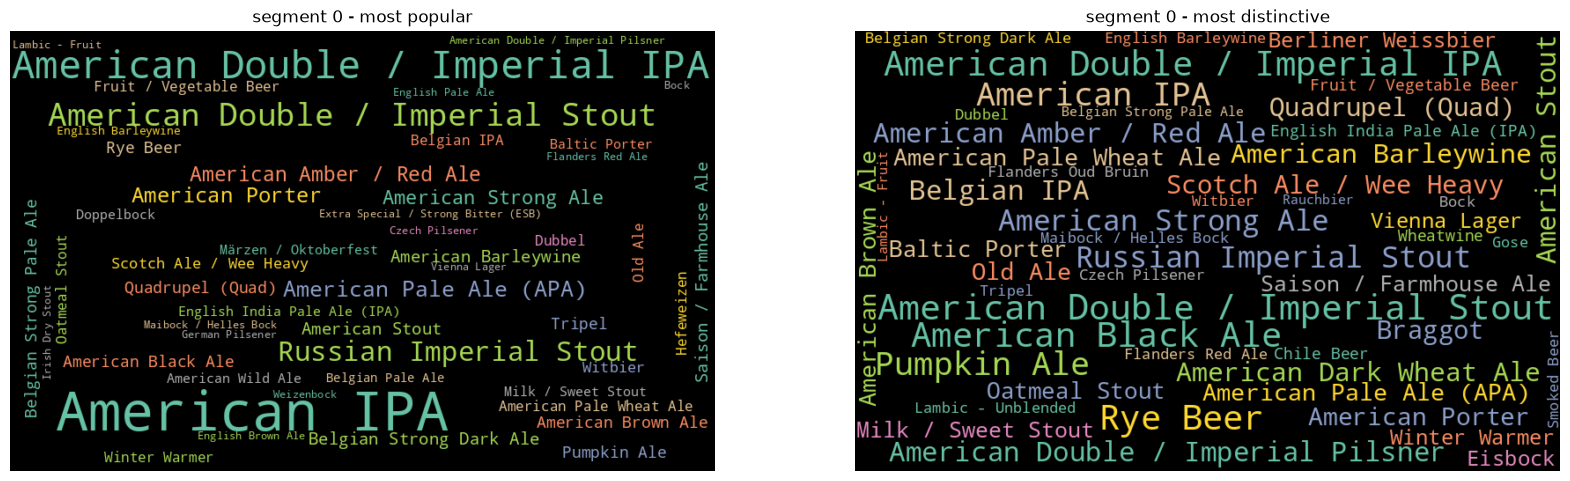

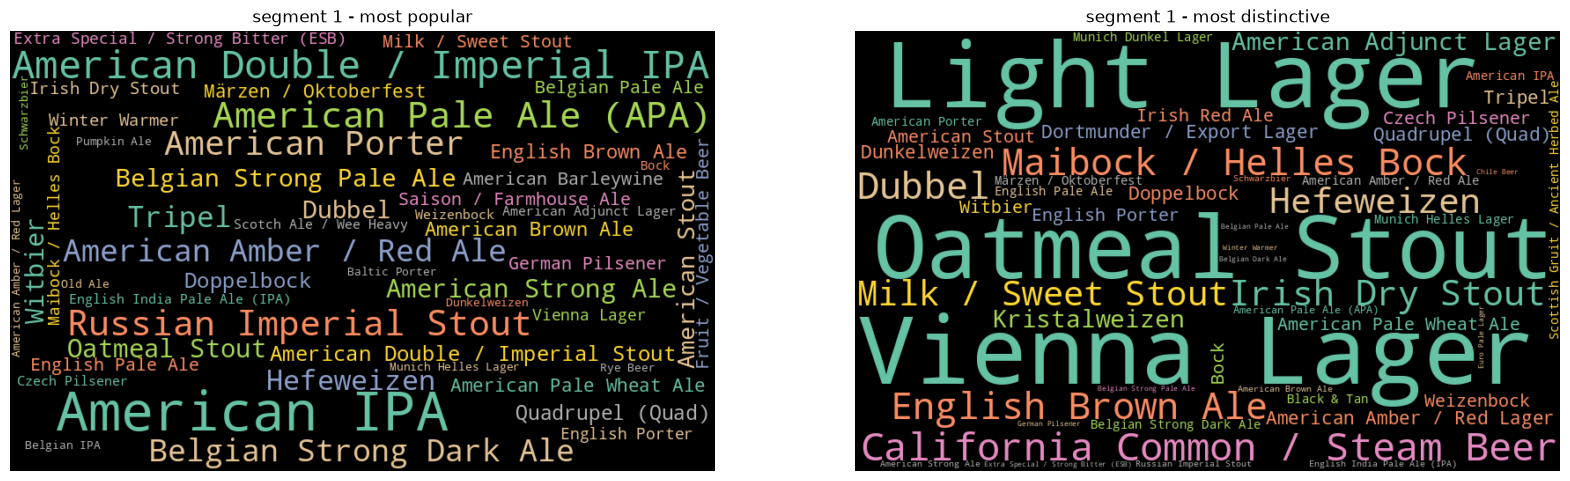

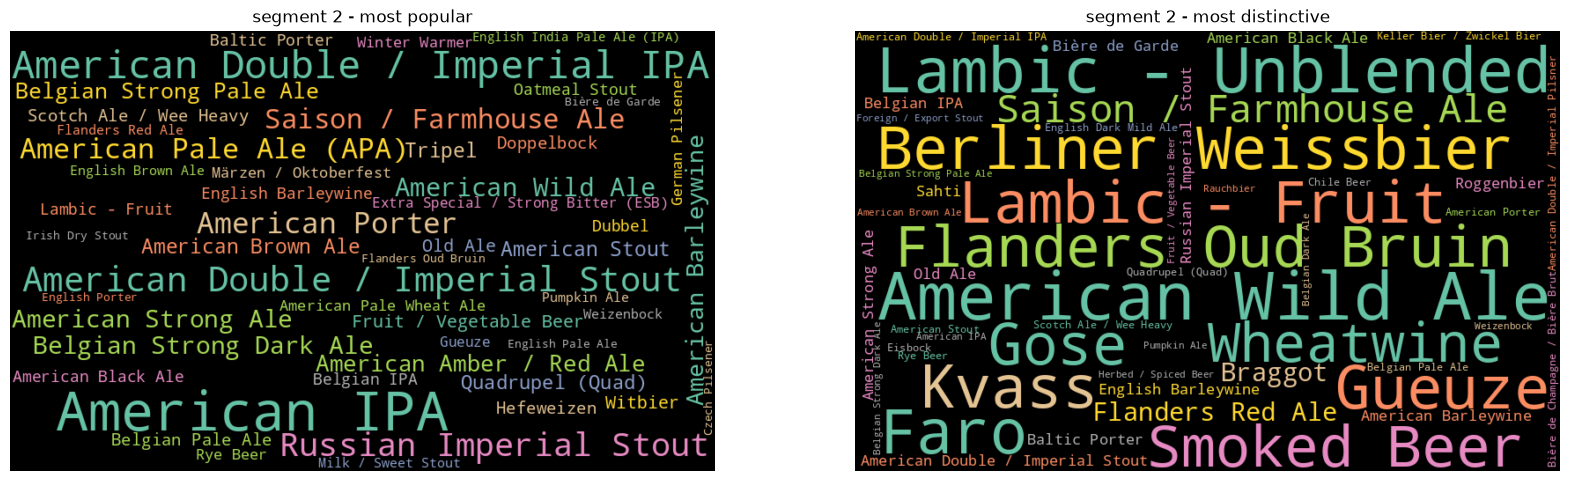

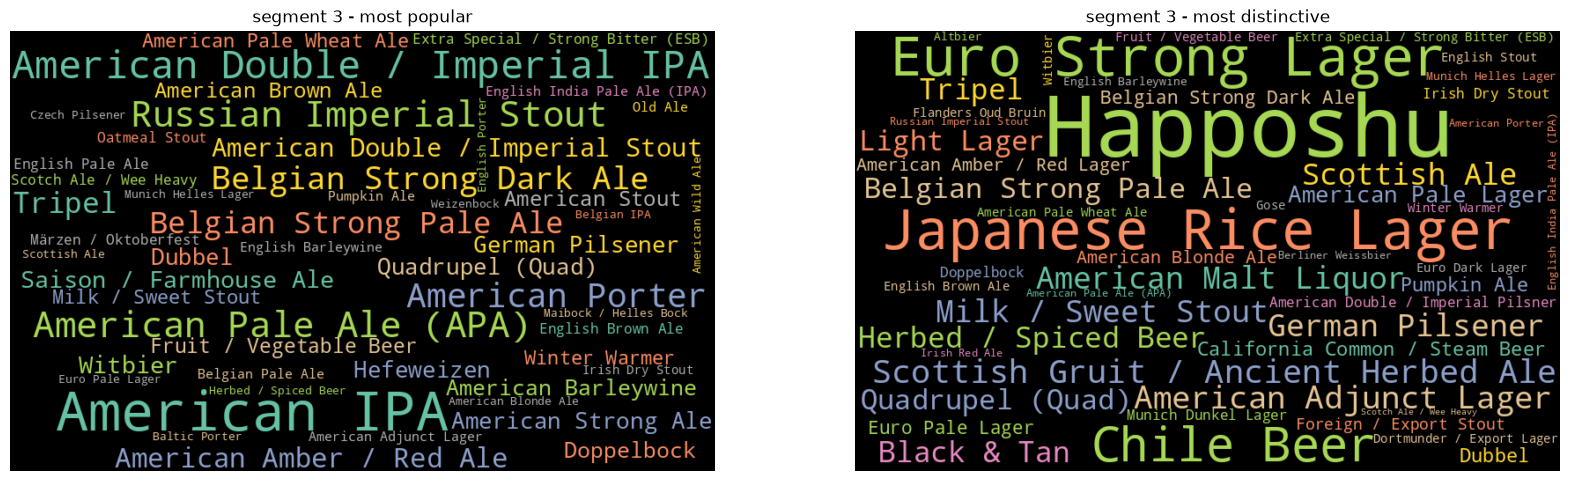

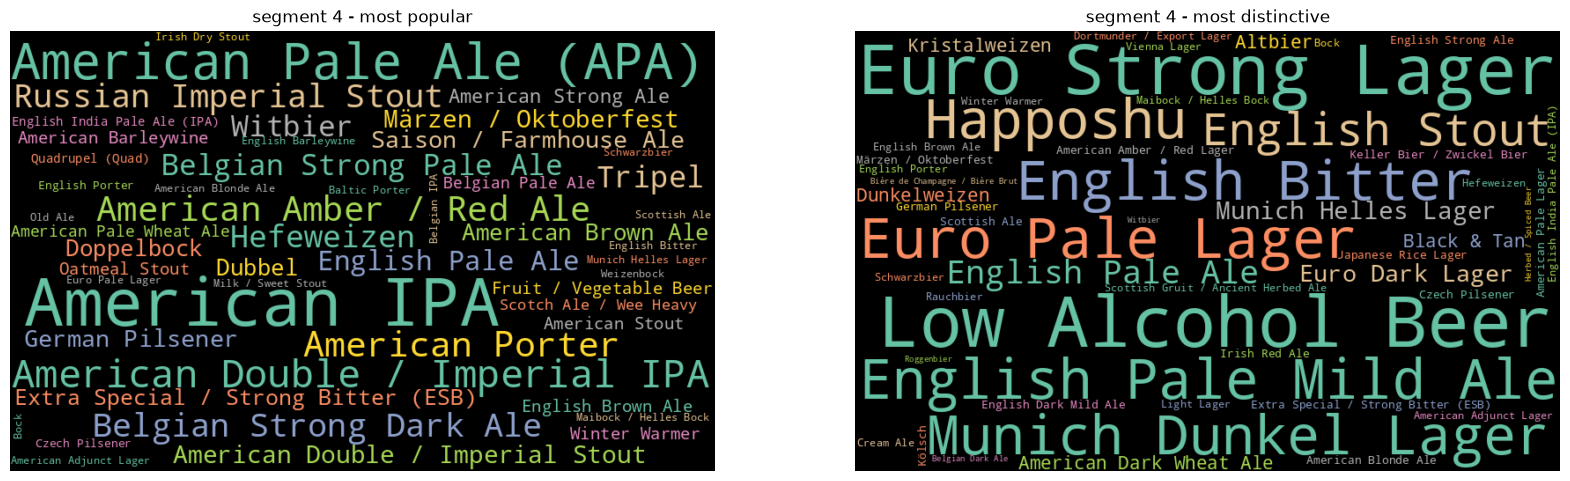

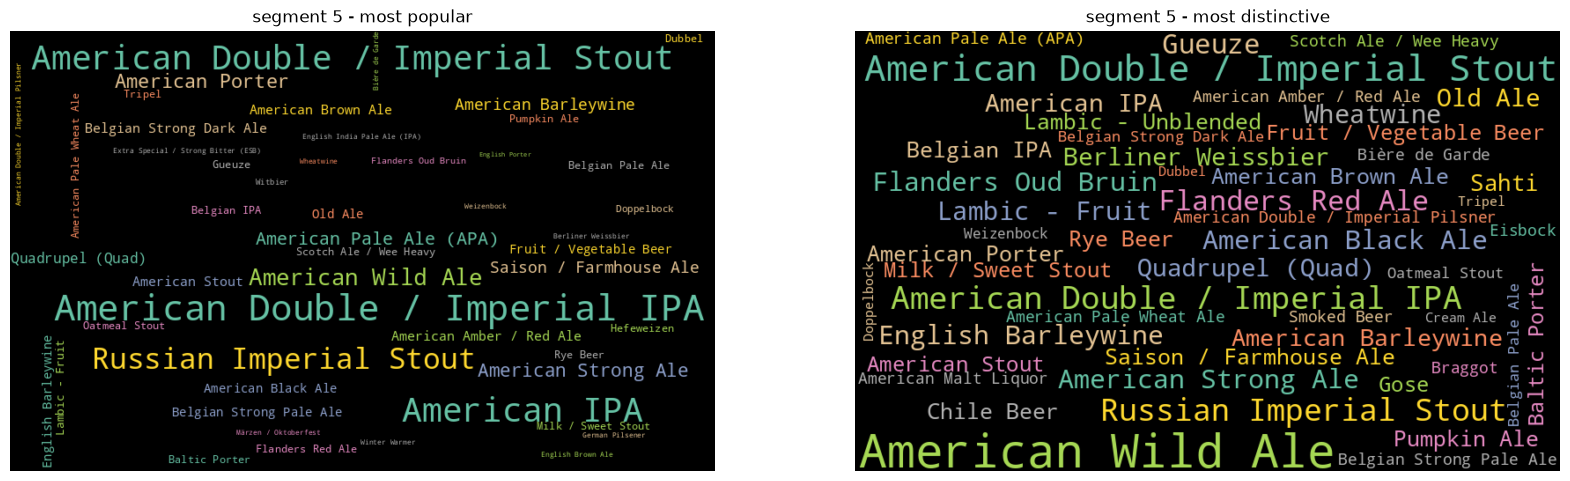

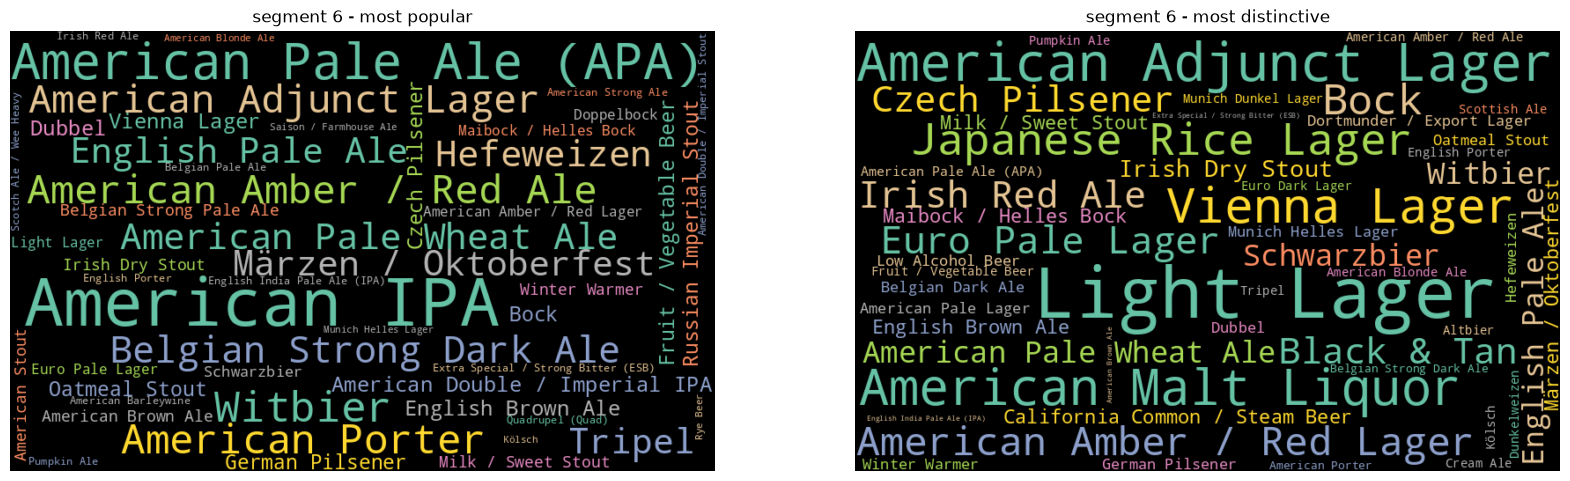

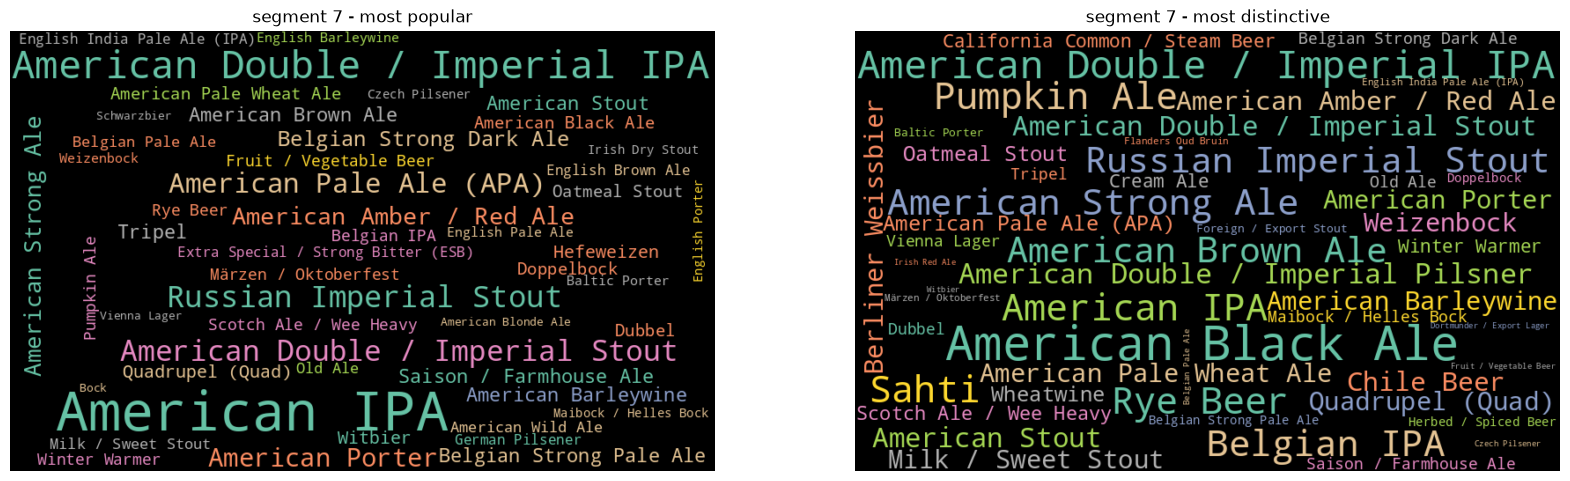

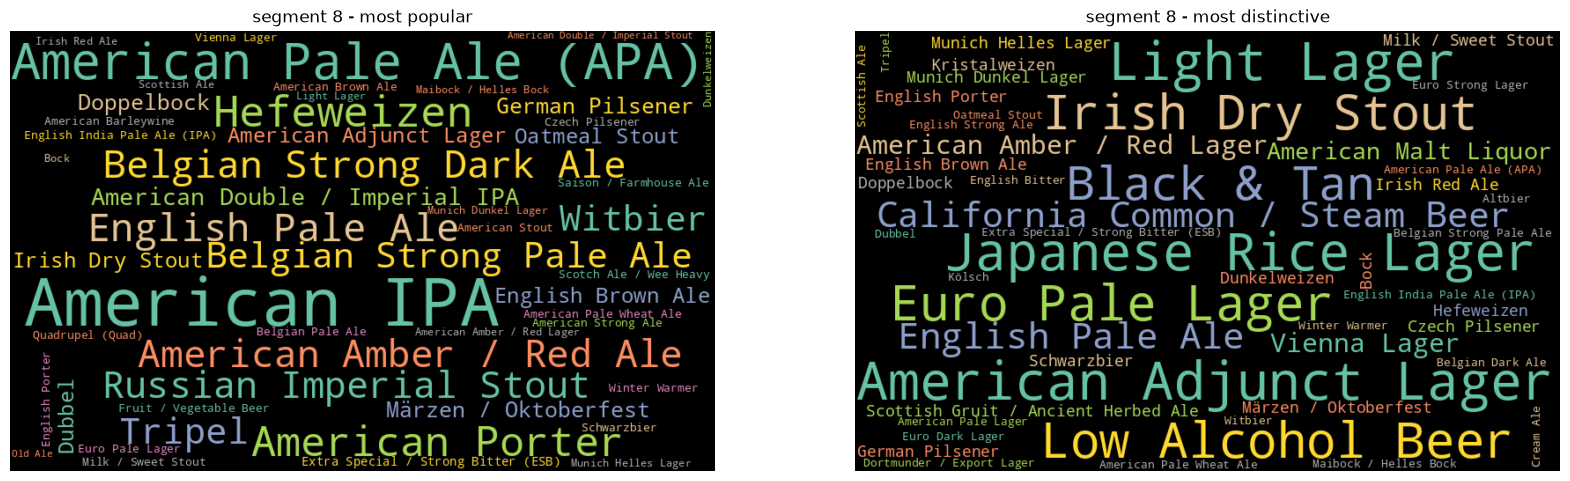

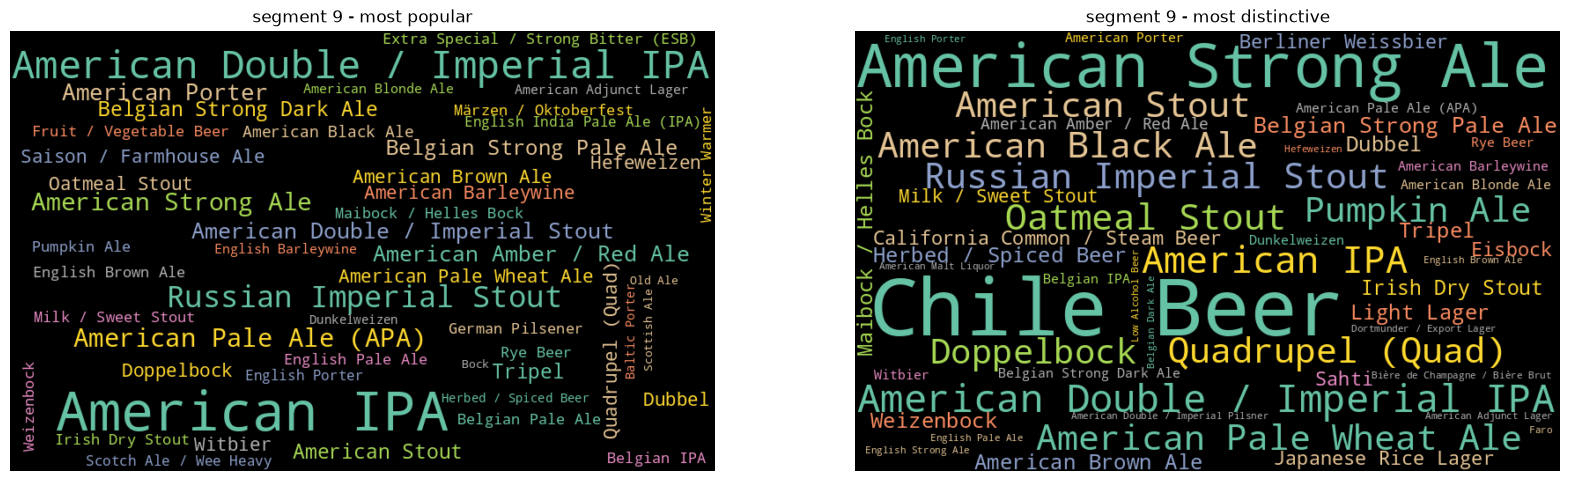

In [86]:
for segment_id in range(0, PARAMS.segments_count):
    plot_segment_wordclouds(most_popular, most_distinctive, segment_id)